# PINN — Physics-Informed Neural Network

Un PINN apprend une solution **directement à partir des équations physiques**, sans données de référence.
Le réseau approxime la solution `u(x)`, et on pénalise le **résidu de l'équation différentielle** calculé par dérivation automatique.

Exemple : résoudre l'EDO `u''(x) + π²·u(x) = 0` avec `u(0) = 0` et `u'(0) = π`, dont la solution exacte est `u(x) = sin(πx)`.

In [1]:
from NeuralNetworks import MLP, Trainer, losses, learnings
import torch

## Points de collocation

Pas de données `y` connues : on fournit seulement les points `x` où l'équation doit être respectée.
Le `Trainer` exige un tenseur `outputs` en 2D — on passe un dummy `[N, 1]` ignoré par le critère.

In [2]:
torch.manual_seed(0)
x = torch.linspace(0, 1, 200).unsqueeze(1)   # points de collocation
dummy = torch.zeros(200, 1)                  # ignoré par le critère PINN

## Critère physique personnalisé

Le `Trainer` accepte **n'importe quel callable** `crit(net, inputs, outputs)` en plus des noms prédéfinis.
Ici la loss combine :

- **résidu physique** : `(u'' + π²u)²` aux points de collocation (dérivées via `torch.autograd.grad`)
- **conditions aux limites** : `u(0)² + (u'(0) − π)²`, pondérées (poids 100)

In [3]:
PI2 = torch.pi ** 2

def pinn_crit(net, xb, _):
    xb = xb.detach().requires_grad_(True)
    u = net.train_forward(xb)
    dudx = torch.autograd.grad(u.sum(), xb, create_graph=True)[0]
    d2u = torch.autograd.grad(dudx.sum(), xb, create_graph=True)[0]
    phys = (d2u + PI2 * u).pow(2).mean()            # résidu de l'EDO
    bc = u[0].pow(2) + (dudx[0] - torch.pi).pow(2)  # u(0)=0, u'(0)=pi
    return phys + 100 * bc

In [4]:
net = MLP(input_size=1, output_size=1, hidden_layers=[32, 32], norm="Tanh", name="PINN")

## Entraînement

On entraîne le `MLP` avec ce critère custom. `Tanh` est bien adapté car la solution est lisse.

In [5]:
trainer = Trainer(net,
                  inputs=x, outputs=dummy,
                  init_train_size=1.0, final_train_size=1.0,
                  crit=pinn_crit, optim="Adam",
                  init_lr=1e-3, final_lr=1e-5,
                  batch_size=200)
trainer.train(2000)

Training PINN:   0%|          | 0/2000 [00:00<?, ?epoch/s]

## Visualiser l'entraînement

Les courbes de perte et de learning rate se tracent avec `losses(net)` et `learnings(net)`.

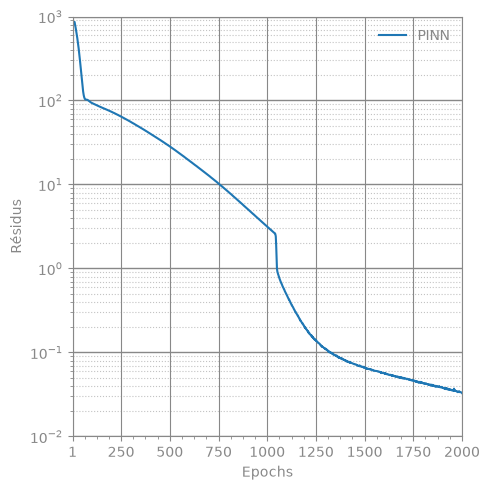

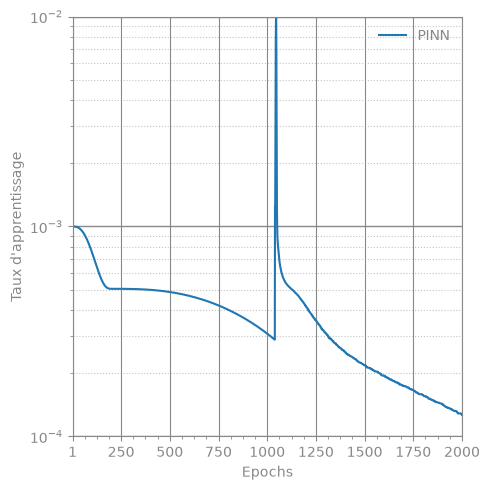

In [6]:
losses(net)
learnings(net)

## Comparaison avec la solution exacte `sin(πx)`

Aucune donnée `sin(πx)` n'a été fournie pendant l'entraînement : le réseau l'a retrouvée uniquement via l'équation.

In [7]:
xt = torch.linspace(0, 1, 100).unsqueeze(1)
y_pred = net(xt)
y_exact = torch.sin(torch.pi * xt)
print("Erreur max vs sin(pi x) :", (y_pred - y_exact).abs().max().item())

Erreur max vs sin(pi x) : 0.012536942958831787
